# 01 — Exploratory Data Analysis: ArSarcasm-v2

This notebook inspects the raw training and test files **before** any preprocessing. All reusable logic lives in `src/bonus/eda.py`; the notebook only calls those helpers and displays their output.

The paper being reproduced is Wadhawan (2021), *AraBERT and Farasa Segmentation Based Approach For Sarcasm and Sentiment Detection in Arabic Tweets* (arXiv 2103.01679), EACL WANLP-2021 Shared Task 2, Subtask 2. The paper reports 12,548 training rows and roughly 17% positive examples.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Walk upwards until the repository root (the folder that contains data/raw) is found.
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from bonus import eda

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
print("Repository root:", ROOT)

Repository root: /home/nour/FCAI-H/fourth year last_dance/Sem1/Neural Networks & deep learning/project


## 1. Load both files

In [2]:
train = eda.load_split(ROOT / eda.RAW_TRAIN_PATH)
test = eda.load_split(ROOT / eda.RAW_TEST_PATH)

for name, frame in [("train", train), ("test", test)]:
    print(f"{name}: shape={frame.shape}")
    print(f"columns={list(frame.columns)}")
    display(frame.head())

train: shape=(12548, 4)
columns=['tweet', 'sarcasm', 'sentiment', 'dialect']


,tweet,sarcasm,sentiment,dialect
0,"""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر...",False,NEU,msa
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...",False,NEU,msa
2,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...,True,NEG,msa
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...",True,NEG,gulf
4,"""قل شرق حلب ولا تقل حلب الشرقية ....وقل غرب حل...",False,NEU,msa


test: shape=(3000, 4)
columns=['tweet', 'sarcasm', 'sentiment', 'dialect']


,tweet,sarcasm,sentiment,dialect
0,اخوي حانق يالغلا وشفيك معصب؟ عادي تراهم بشر يف...,False,NEG,msa
1,اف مو متعوده عليهم سته https://t.co/8igFPx1i26,True,NEG,msa
2,اللهم اشفِ مرضانا ومرضى المسلمين . . ♥️,False,POS,msa
3,ابشركم طلقت السات 😘.,False,POS,gulf
4,مؤشر خطير: ٩٠٪ من الشخصيات البرلمانية في الكوي...,True,NEG,msa


## 2. Does the test file contain real sentiment labels?

The test file is checked for missing, empty, or placeholder sentiment values. The observed labels are compared with the three valid ArSarcasm-v2 labels: `POS`, `NEG`, and `NEU`. A held-out-gold warning is printed only for the test split.

In [3]:
for name, frame in [("train", train), ("test", test)]:
    check = eda.check_sentiment_labels(frame)
    print(f"=== {name} sentiment check ===")
    for key, value in check.items():
        print(f"{key}: {value}")
    if name == "test":
        print("NOTE: Test labels are held-out gold; they are never used for training, tuning, or model selection.")
    print()

=== train sentiment check ===
has_column: True
rows: 12548
non_null: 12548
empty: 0
invalid_values: []
observed_labels: ['NEG', 'NEU', 'POS']
is_usable: True
verdict: VALID SENTIMENT LABELS

=== test sentiment check ===
has_column: True
rows: 3000
non_null: 3000
empty: 0
invalid_values: []
observed_labels: ['NEG', 'NEU', 'POS']
is_usable: True
verdict: VALID SENTIMENT LABELS
NOTE: Test labels are held-out gold; they are never used for training, tuning, or model selection.



## 3. Sentiment distribution

Counts and percentages are shown for the training set and for the labelled test set. The final comparison line checks the two figures quoted in the paper: 12,548 training rows and about 17% positive examples.

Train sentiment distribution


,count,percentage
sentiment,,
POS,2180,17.37
NEG,4621,36.83
NEU,5747,45.80


Test sentiment distribution


,count,percentage
sentiment,,
POS,575,19.17
NEG,1677,55.90
NEU,748,24.93


Training rows: 12,548 (paper: 12,548)
POS share: 17.37% (paper: about 17%)


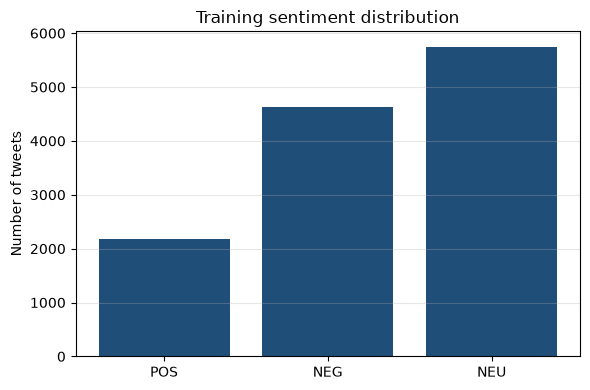

In [4]:
train_sentiment = eda.sentiment_distribution(train)
test_sentiment = eda.sentiment_distribution(test)

print("Train sentiment distribution")
display(train_sentiment.round(2))
print("Test sentiment distribution")
display(test_sentiment.round(2))

pos_share = train_sentiment.loc["POS", "percentage"]
print(f"Training rows: {len(train):,} (paper: 12,548)")
print(f"POS share: {pos_share:.2f}% (paper: about 17%)")

fig = eda.plot_category_counts(train_sentiment["count"], "Training sentiment distribution")
plt.show()

## 4. Tweet length in characters and whitespace tokens

Character length is the number of Unicode code points. Whitespace-token length is the number of tokens produced by Python's `str.split()`.

Train length statistics


,chars,whitespace_tokens
count,12548.00,12548.00
mean,102.90,15.04
std,38.16,6.77
min,4.00,1.00
25%,78.00,10.00
50%,108.00,15.00
75%,133.00,20.00
max,303.00,61.00


,chars,whitespace_tokens
0.50,108.0,15.0
0.90,140.0,23.0
0.95,142.0,25.0
0.99,212.5,35.5


Test length statistics


,chars,whitespace_tokens
count,3000.00,3000.00
mean,101.11,16.85
std,58.40,10.44
min,2.00,1.00
25%,58.00,9.00
50%,97.00,16.00
75%,126.00,22.00
max,304.00,57.00


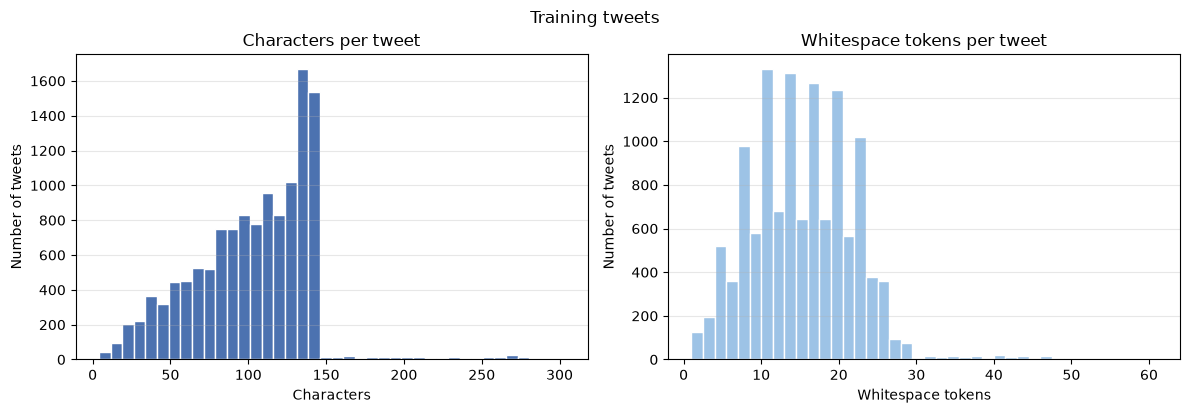

In [5]:
train_lengths = eda.text_lengths(train)
test_lengths = eda.text_lengths(test)

print("Train length statistics")
display(train_lengths.describe().round(2))
display(train_lengths.quantile([0.5, 0.9, 0.95, 0.99]).round(1))

print("Test length statistics")
display(test_lengths.describe().round(2))

fig = eda.plot_text_length_histograms(train_lengths)
fig.suptitle("Training tweets", y=1.02)
plt.show()

## 5. How many tweets exceed the 256-token limit?

Each tweet is tokenized with the AraBERT tokenizer (`aubmindlab/bert-base-arabertv02`) without truncation. The reported length includes the special `[CLS]` and `[SEP]` tokens. The token lengths are reused for the marker breakdown below.

In [6]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(eda.ARABERT_MODEL_NAME)
token_lengths_by_split = {}

for name, frame in [("train", train), ("test", test)]:
    lengths = eda.tokenizer_lengths(frame["tweet"].tolist(), tokenizer)
    token_lengths_by_split[name] = lengths
    stats = eda.summarize_token_lengths(lengths, max_length=256)
    print(f"=== {name} AraBERT token lengths ===")
    for key, value in stats.items():
        print(f"{key}: {value}")
    print()

/home/nour/py/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== train AraBERT token lengths ===
n_texts: 12548
max_length_limit: 256
max_observed: 152
mean_observed: 38.836467963021995
median_observed: 37.0
over_limit_count: 0
over_limit_percentage: 0.0

=== test AraBERT token lengths ===
n_texts: 3000
max_length_limit: 256
max_observed: 173
mean_observed: 31.978
median_observed: 30.0
over_limit_count: 0
over_limit_percentage: 0.0



### Why is the AraBERT tokens-per-word ratio higher for train?

URLs, mentions, and hashtags are often split into several AraBERT pieces. This cell reports how common each marker is in each split, together with the aggregate tokens-per-word ratio for tweets with and without the marker.

In [7]:
for name, frame in [("train", train), ("test", test)]:
    lengths = token_lengths_by_split[name]
    words = frame["tweet"].str.split().str.len().to_numpy()
    overall_ratio = lengths.sum() / words.sum()
    print(f"=== {name}: overall tokens/word = {overall_ratio:.2f} ===")
    display(eda.marker_breakdown(frame, lengths).round(2))

=== train: overall tokens/word = 2.58 ===


,marker,tweet_count,share_pct,tokens_per_word_with,tokens_per_word_without
0,url,4801,38.26,4.09,1.83
1,mention,2883,22.98,2.91,2.48
2,hashtag,5771,45.99,3.02,2.24


=== test: overall tokens/word = 1.90 ===


,marker,tweet_count,share_pct,tokens_per_word_with,tokens_per_word_without
0,url,440,14.67,3.71,1.69
1,mention,19,0.63,3.44,1.89
2,hashtag,960,32.00,1.97,1.85


## 6. Duplicates, missing values, and train/test overlap

Duplicates are measured with exact string equality. The exact overlap is reported first, followed by a normalized overlap that strips leading/trailing whitespace and collapses internal whitespace runs.

In [8]:
for name, frame in [("train", train), ("test", test)]:
    print(f"=== {name} duplicates ===")
    print(eda.duplicate_summary(frame))
    print(f"=== {name} missing values ===")
    display(eda.missing_summary(frame).round(2))
    print()

exact_overlap = eda.tweet_overlap(train, test)
normalized_overlap = eda.tweet_overlap(train, test, normalize=True)

print("=== Train/test tweet overlap: exact ===")
for key, value in exact_overlap.items():
    print(f"{key}: {value}")

print("=== Train/test tweet overlap: normalized whitespace ===")
for key, value in normalized_overlap.items():
    print(f"{key}: {value}")

=== train duplicates ===
{'full_row_duplicates': 16, 'tweet_duplicates': 61, 'unique_tweets': 12487}
=== train missing values ===


,column,dtype,missing,empty_strings,missing_or_empty_pct
0,tweet,str,0,0,0.0
1,sarcasm,bool,0,0,0.0
2,sentiment,str,0,0,0.0
3,dialect,str,0,0,0.0



=== test duplicates ===
{'full_row_duplicates': 2, 'tweet_duplicates': 4, 'unique_tweets': 2996}
=== test missing values ===


,column,dtype,missing,empty_strings,missing_or_empty_pct
0,tweet,str,0,0,0.0
1,sarcasm,bool,0,0,0.0
2,sentiment,str,0,0,0.0
3,dialect,str,0,0,0.0


=== Train/test tweet overlap: exact ===
train_unique: 12487
test_unique: 2996
overlap_count: 2
overlap_percentage_of_test: 0.06675567423230974
examples: ['الصحافة أحاديث مع أناس يحسنون الكلام ننشرها علي أناس لايحسنون القراءة. أنيس منصور  ', 'سبحان الله ميدان مصطفى محمود هو الملاذ الاخير لكل المغضوب عليهم من الشعب !   القدر #فلول #اخوان']
=== Train/test tweet overlap: normalized whitespace ===
train_unique: 12487
test_unique: 2996
overlap_count: 2
overlap_percentage_of_test: 0.06675567423230974
examples: ['الصحافة أحاديث مع أناس يحسنون الكلام ننشرها علي أناس لايحسنون القراءة. أنيس منصور', 'سبحان الله ميدان مصطفى محمود هو الملاذ الاخير لكل المغضوب عليهم من الشعب ! القدر #فلول #اخوان']


### Repeated training tweets with conflicting sentiment labels

The table above counts duplicate tweets but does not show whether the duplicates agree on the label. This cell reports exact repeated tweets whose sentiment labels are not all the same.

In [9]:
conflicts = eda.conflicting_sentiment_duplicates(train)
print(f"Conflicting repeated tweets: {conflicts['conflicting_tweet_count']}")
print(f"Rows involved: {conflicts['conflicting_row_count']}")
print("Examples:")
for example in conflicts["examples"]:
    print(f"- labels: {example['labels']}")
    print(f"  tweet: {example['tweet'][:180]}")

Conflicting repeated tweets: 25
Rows involved: 50
Examples:
- labels: NEU=1, POS=1
  tweet: "@msgogoksa @AbduIrahmanSaud اردوغان سياسي محنك غير سيسي مصر بيقدر يعمل اللى هو عايزه وبيلعبها صح.."
- labels: POS=1, NEU=1
  tweet: "RT @A822822A: الجيش الحر السوري يرسل رساله لروافض #العراق و #إيران  و #لبنان ♦️هذا مصير ونهاية من يدخل #حلب الحريه حلب الإسلام👌 #سوريا #بغ…"
- labels: NEG=1, NEU=1
  tweet: "RT @A822822A: بعد شرب الكحول يأتي دور التطبير♦️♦️#الشيعه #العراق #بغداد #كربلاء #النجف #لبنان #سوريا #حلب #البحرين #الكويت #قطر #الجزائر #…"
- labels: NEG=1, NEU=1
  tweet: "RT @A822822A: ياروافض بلا كلام وإلا سوف أخرج♦️♦️#العراق #بغداد #البصره #كربلاء #النجف #لبنان #البحرين #الكويت #قطر #سوريا #عمان #الأردن ht…"
- labels: NEG=1, NEU=1
  tweet: "RT @Ahmed2I3h: وتتابع صحيفة النيويورك تايمزالتي خلقت كارثة إنسانية في أحد أفقر بلدان العالم  وإثارة الإرهاب ، والأمر بيد الرئيس #أوباما لي…"


## 7. Dialect distribution

Train dialect distribution


,count,percentage
dialect,,
msa,8562,68.23
egypt,2675,21.32
gulf,644,5.13
levant,624,4.97
magreb,43,0.34


Test dialect distribution


,count,percentage
dialect,,
msa,2323,77.43
gulf,322,10.73
egypt,306,10.20
levant,47,1.57
magreb,2,0.07


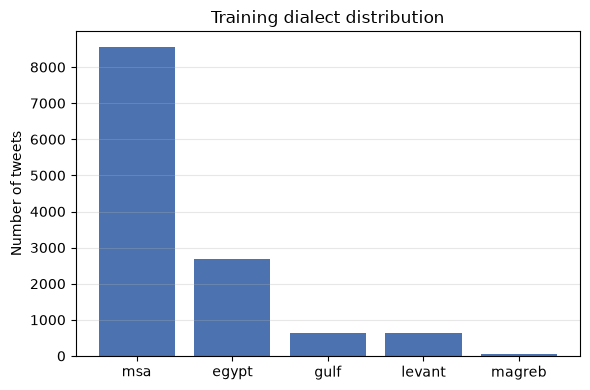

In [10]:
train_dialect = eda.dialect_distribution(train)
test_dialect = eda.dialect_distribution(test)

print("Train dialect distribution")
display(train_dialect.round(2))
print("Test dialect distribution")
display(test_dialect.round(2))

fig = eda.plot_category_counts(
    train_dialect["count"],
    "Training dialect distribution",
    color=eda.BLUE_MEDIUM,
)
plt.show()

## 8. Summary

- The training file has **12,548 rows** and the test file has **3,000 rows**, with the expected columns `tweet`, `sarcasm`, `sentiment`, and `dialect`.
- The test sentiment column contains **valid labels** (`POS`, `NEG`, `NEU`), not placeholders. These labels are treated as held-out gold and will only be read by the separate final evaluation function.
- The training sentiment distribution is **POS 2,180 (17.37%)**, **NEG 4,621 (36.83%)**, and **NEU 5,747 (45.80%)**. The row count and positive share match the paper.
- **Train vs test label shift:** test is **POS 575 (19.17%)**, **NEG 1,677 (55.90%)**, and **NEU 748 (24.93%)**. The test set is much more negative and much less neutral than train, so validation-derived model selection may not transfer perfectly to test.
- No tweet exceeds 256 AraBERT tokens (maximum observed: 152 for train, 173 for test), so truncation should not remove content.
- There are no NaN or empty values. Exact duplicates exist (16 full rows / 61 tweets in train, 2 / 4 in test). **25 repeated training tweets (50 rows)** have conflicting sentiment labels.
- Two tweet strings appear in both train and test under exact matching, and the same two remain after stripping and collapsing whitespace (0.07% of the test set).
- The train tokens-per-word ratio is higher than test (**2.58 vs 1.90**). Train has far more URLs (**38.26% vs 14.67%**) and mentions (**22.98% vs 0.63%**), and slightly more hashtags (**45.99% vs 32.00%**). Tweets containing URLs have a much higher tokens-per-word ratio, which explains most of the gap.
- MSA dominates the training dialects (68.23%), followed by Egyptian (21.32%), Gulf (5.13%), Levantine (4.97%), and Maghrebi (0.34%).